---
title: "Лабораторна робота 2. Побудова базової моделі та проєктування ML-експерименту"
description: "Машинне навчання та методи вилучення знань | PhD F3 «Комп'ютерні науки» | КрНУ ім. М. Остроградського"
author: "&copy; [Valeriy Sydorenko](https://www.linkedin.com/in/valeriy-sydorenko-6782279a/), 2026"
date: today
jupyter: python3
bibliography: mlkdd-references.bib
format:
  html:
    code-fold: show
    code-summary: "Показати код"
    code-overflow: wrap
    toc: true
    toc-depth: 4
    toc-location: right
    number-sections: false
    embed-resources: true
    smooth-scroll: true
---


::: {.callout-note}
## Примітка
ЛР2 продовжує ЛР1 та спирається на Лекцію 2. У ЛР1 сформовано первинну специфікацію
$$RQ\rightarrow\text{тип твердження}\rightarrow\text{ML/KDD-задача}\rightarrow\text{дані}\rightarrow\text{критерій доказовості}.$$
Тепер додаємо:
$$\text{Research Specification}\rightarrow\text{Baseline}\rightarrow\text{Validation Design}\rightarrow\text{Metrics}\rightarrow\text{Uncertainty}\rightarrow\text{Evidence}.$$
:::

## Мета роботи
Набути практичної здатності будувати відтворювану базову модель (*baseline model*) та проєктувати ML-експеримент як складову наукового дослідження: формувати коректну схему розбиття даних, обирати метрики відповідно до дослідницького питання, оцінювати варіативність результатів і відокремлювати покращення прогнозної якості від науково значущого результату.

## Завдання роботи
1. Перевести специфікацію ЛР1 у формальний експериментальний протокол.
2. Побудувати naive та model baseline.
3. Визначити train/validation/test design.
4. Реалізувати pipeline без *data leakage*.
5. Зафіксувати primary та secondary metrics.
6. Оцінити варіативність результатів.
7. Порівняти baseline з альтернативною моделлю.
8. Провести критичний аудит висновків.
9. Перенести процедуру на власне дисертаційне дослідження.
10. Оновити наскрізний артефакт до версії 0.2.

::: {.callout-important}
## Методологічний принцип
*Спочатку протокол -- потім результат.* Метрики, правила розбиття, baseline і критерій порівняння фіксуються до аналізу підсумкового результату.
:::

## Теоретичні відомості
Для вибірки $D=\{(x_i,y_i)\}_{i=1}^n$ нас цікавить не лише навчальна помилка, а очікуваний ризик
$$R(f)=\mathbb{E}_{(X,Y)\sim P}[L(Y,f(X))].$$
Тому validation design визначає, яку майбутню ситуацію імітує експеримент і до якого домену можна переносити висновок [@hastie2009elements; @bishop2006prml].

### Логіка лабораторної роботи
```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 R("Research<br/>Specification v0.1") --> B("Baseline")
 B --> V("Validation<br/>design")
 V --> M("Metrics")
 M --> E("ML<br/>experiment")
 E --> U("Uncertainty")
 U --> A("Critical<br/>audit")
 A --> O("Experiment<br/>Design v0.2")
```

# Частина I. Навчальний кейс
Використаємо бінарну класифікацію Breast Cancer Wisconsin із `scikit-learn`. Питання: *чи дає проста модель відтворювану прогнозну якість у межах цього набору даних?* Це прогнозне, а не причинне питання.

## 1. Завантаження та первинний аудит даних


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score, confusion_matrix

RANDOM_STATE = 42
data = load_breast_cancer(as_frame=True)
X, y = data.data.copy(), data.target.copy()
print("Розмір X:", X.shape)
print("Класи:", dict(zip(data.target_names, np.bincount(y))))
print("Пропущені значення:", int(X.isna().sum().sum()))
X.head()


Розмір X: (569, 30)
Класи: {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}
Пропущені значення: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### Завдання 1.1
Заповніть: одиниця спостереження; target; тип ML-задачі; домен узагальнення; підтримуване та непідтримуване твердження.

## 2. Відкладена тестова вибірка


In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Частка класу 1:", round(y.mean(),3), round(y_train.mean(),3), round(y_test.mean(),3))


Train: (455, 30) Test: (114, 30)
Частка класу 1: 0.627 0.626 0.632


### Завдання 2.1
Поясніть роль test set, стратифікації та наведіть випадки, коли random split методологічно неправильний.

## 3. Naive baseline


In [3]:
dummy=DummyClassifier(strategy="most_frequent").fit(X_train,y_train)
p=dummy.predict(X_test)
print("Dummy accuracy =", round(accuracy_score(y_test,p),3))
print("Dummy balanced accuracy =", round(balanced_accuracy_score(y_test,p),3))


Dummy accuracy = 0.632
Dummy balanced accuracy = 0.5


## 4. Модельний baseline: логістична регресія
Стандартизацію включаємо до `Pipeline`: preprocessing не повинен «бачити» validation/test дані.


In [4]:
baseline=Pipeline([
 ("scale",StandardScaler()),
 ("model",LogisticRegression(max_iter=5000,random_state=RANDOM_STATE))
])
baseline.fit(X_train,y_train)
pred=baseline.predict(X_test); prob=baseline.predict_proba(X_test)[:,1]
print("Accuracy =",round(accuracy_score(y_test,pred),3))
print("Balanced accuracy =",round(balanced_accuracy_score(y_test,pred),3))
print("ROC AUC =",round(roc_auc_score(y_test,prob),3))


Accuracy = 0.982
Balanced accuracy = 0.981
ROC AUC = 0.995


::: {.callout-important}
## `Pipeline` як частина методології
Preprocessing на всій вибірці до CV створює *data leakage*. Pipeline кодує частину експериментального протоколу.
:::

## 5. Метрики визначаємо до порівняння моделей
Primary metric -- ROC AUC; допоміжні -- balanced accuracy та accuracy.

### Завдання 5.1
Чому метрика має випливати з RQ та ціни помилок, а не вибиратися після перегляду результатів?

## 6. Крос-валідація та варіативність


In [5]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE)
scoring={"roc_auc":"roc_auc","balanced_accuracy":"balanced_accuracy","accuracy":"accuracy"}
rb=cross_validate(baseline,X_train,y_train,cv=cv,scoring=scoring)
cvb=pd.DataFrame({"fold":range(1,6),"ROC AUC":rb["test_roc_auc"],
 "Balanced accuracy":rb["test_balanced_accuracy"],"Accuracy":rb["test_accuracy"]})
display(cvb.round(3))
display(cvb.drop(columns="fold").agg(["mean","std"]).T.round(4))


,fold,ROC AUC,Balanced accuracy,Accuracy
0,1,0.986,0.956,0.967
1,2,0.999,0.991,0.989
2,3,0.997,0.977,0.978
3,4,0.999,0.985,0.989
4,5,0.998,0.968,0.967


,mean,std
ROC AUC,0.9959,0.0055
Balanced accuracy,0.9753,0.0140
Accuracy,0.9780,0.0110


### Завдання 6.1
Порівняйте single split та CV mean ± SD. Чого CV mean ± SD усе ще не доводить?

## 7. Альтернативна модель


In [6]:
alternative=RandomForestClassifier(n_estimators=500,min_samples_leaf=2,
 random_state=RANDOM_STATE,n_jobs=-1)
ra=cross_validate(alternative,X_train,y_train,cv=cv,scoring=scoring)
cmp=pd.DataFrame({"fold":range(1,6),"Baseline ROC AUC":rb["test_roc_auc"],
 "Alternative ROC AUC":ra["test_roc_auc"]})
cmp["Delta"]=cmp["Alternative ROC AUC"]-cmp["Baseline ROC AUC"]
display(cmp.round(4))
print("Mean Delta =",round(cmp["Delta"].mean(),4)," SD =",round(cmp["Delta"].std(ddof=1),4))


,fold,Baseline ROC AUC,Alternative ROC AUC,Delta
0,1,0.9861,0.9881,0.0021
1,2,0.9990,0.9974,-0.0015
2,3,0.9969,0.9861,-0.0108
3,4,0.9990,0.9794,-0.0196
4,5,0.9985,0.9974,-0.0010


Mean Delta = -0.0062  SD = 0.0089


### Завдання 7.1
Сформулюйте обережний висновок: за якою метрикою, у межах якої процедури, яка величина та стабільність різниці?

## 8. Візуалізація варіативності


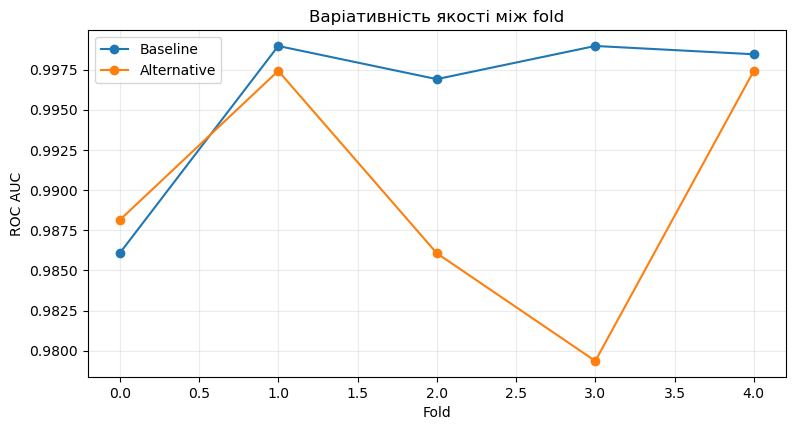

In [7]:
ax=pd.DataFrame({"Baseline":rb["test_roc_auc"],"Alternative":ra["test_roc_auc"]}).plot(
 marker="o",figsize=(9,4.5))
ax.set_xlabel("Fold"); ax.set_ylabel("ROC AUC"); ax.set_title("Варіативність якості між fold")
ax.grid(alpha=0.25); plt.show()


## 9. Фінальна оцінка на test set
Test set використовуємо після завершення модельних рішень.


In [8]:
baseline.fit(X_train,y_train); alternative.fit(X_train,y_train)
rows=[]
for name,model in [("Logistic Regression",baseline),("Random Forest",alternative)]:
 pr=model.predict(X_test); pp=model.predict_proba(X_test)[:,1]
 rows.append({"model":name,"accuracy":accuracy_score(y_test,pr),
 "balanced_accuracy":balanced_accuracy_score(y_test,pr),"roc_auc":roc_auc_score(y_test,pp)})
pd.DataFrame(rows).round(4)


,model,accuracy,balanced_accuracy,roc_auc
0,Logistic Regression,0.9825,0.9812,0.9954
1,Random Forest,0.9561,0.9504,0.9937


### Завдання 9.1
Чи узгоджується test-результат із CV? Чи достатньо цього для перенесення висновку на іншу популяцію, установу або часовий період?

## 10. Матриця помилок


In [9]:
pd.DataFrame(confusion_matrix(y_test,baseline.predict(X_test)),
 index=["Фактичний 0","Фактичний 1"],columns=["Прогноз 0","Прогноз 1"])


,Прогноз 0,Прогноз 1
Фактичний 0,41,1
Фактичний 1,1,71


### Завдання 10.1
Інтерпретуйте типи помилок у предметних термінах і поясніть залежність порогу від контексту.

## 11. Критичний аудит навчального експерименту
Заповніть аудит: baseline; primary metric; validation; leakage; fold variability; величина покращення; домен узагальнення; невизначеність; підтримуване та надмірне твердження.

::: {.callout-warning}
## Межа висновку
$$\text{feature importance}\not\Rightarrow\text{causal importance}.$$
Внутрішня CV одного dataset не є автоматичним доказом зовнішньої валідності [@breiman2001two].
:::

# Частина II. Перенесення на дисертаційне дослідження

## 12. Research Specification v0.1
Перенесіть із ЛР1: RQ; тип твердження; одиницю аналізу; ML/KDD-задачу; дані; target; представлення; домен узагальнення; критерій доказовості. Зміни фіксуйте як нову версію з поясненням.

## 13. Проєктування baseline

| Рівень | Модель / правило | Навіщо потрібний |
|---|---|---|
| Naive baseline | | |
| Model/domain baseline | | |
| Candidate model | | |

### Завдання 13.1
Яке додаткове твердження стане можливим, якщо candidate model стабільно перевищить baseline?

## 14. Validation design
```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart TD
 D("Яка структура<br/>даних?") --> I{"Спостереження<br/>незалежні?"}
 I -->|Так| S("Random / stratified<br/>split або CV")
 I -->|Ні| G{"Джерело<br/>залежності?"}
 G -->|Час| T("Temporal / rolling<br/>validation")
 G -->|Групи| C("Group-based<br/>validation")
 G -->|Домени| E("External / domain<br/>validation")
```
Зафіксуйте train, validation, test, grouping/stratification, temporal restrictions, external validation і seed policy.

## 15. Аудит data leakage

| Потенційний leakage | Є ризик? | Як усувається |
|---|---:|---|
| Масштабування до split/CV | | |
| Feature selection на всій вибірці | | |
| Imputation на всій вибірці | | |
| Target-derived features | | |
| Повторні об'єкти в train/test | | |
| Майбутня інформація в ознаках | | |
| Рішення після перегляду test | | |
| Доменно-специфічні джерела | | |

## 16. Метрики та критерій успіху
До основного порівняння зафіксуйте primary metric, secondary metrics, practically meaningful difference, спосіб оцінки uncertainty і правило порівняння з baseline.

## 17. Мінімальний відтворюваний pipeline
Реалізуйте preprocessing, feature construction і model без використання validation/test інформації. Для часових рядів, графів, текстів або мультимодальних даних адаптуйте pipeline до своєї задачі.

## 18. Мінімальний експеримент
$$	ext{baseline}\quad	ext{vs}\quad	ext{candidate model}.$$

| Run / fold | Baseline | Candidate | Delta |
|---|---:|---:|---:|
| 1 | | | |
| 2 | | | |
| ... | | | |
| Mean | | | |
| SD | | | |

### Завдання 18.1
Сформулюйте висновок: validation design; primary metric; величина зміни; стабільність; підтримуване і непідтримуване твердження.

## 19. Аудит експериментального дизайну
1. Яке припущення найсильніше?
2. Яке рішення найбільше впливає на якість?
3. Яке джерело leakage найнебезпечніше?
4. Що може бути артефактом split?
5. Що потрібно для зовнішньої валідності?
6. Яке твердження Ви свідомо не робите?

## 20. Оновлення наскрізного артефакту
```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 R("RQ") --> T("Тип<br/>твердження")
 T --> K("ML/KDD<br/>задача")
 K --> D("Дані")
 D --> B("Baseline")
 B --> V("Validation<br/>design")
 V --> M("Metrics")
 M --> U("Uncertainty")
 U --> E("Evidence<br/>v0.2")
```

## 21. Підсумковий артефакт ЛР2
Підготуйте **ML Experiment Design v0.2**: RQ; тип твердження; ML/KDD-задача; дані; naive і model/domain baseline; candidate model; train/validation/test; leakage audit; metrics; uncertainty; мінімальний експеримент; межі узагальнення; одне підтримуване та одне непідтримуване твердження.

Артефакт стане входом до ЛР3 -- *«Валідація та аудит достовірності результатів машинного навчання»*.

# Контрольні питання
1. Чому train quality не доводить узагальнення?
2. Яку роль виконує baseline?
3. Чим naive baseline відрізняється від model/domain baseline?
4. Чому preprocessing має бути всередині validation pipeline?
5. Що таке data leakage?
6. Чому random split не універсальний?
7. Що додає CV порівняно з одним split?
8. Чому CV mean ± SD не є автоматично довірчим інтервалом?
9. Чому primary metric фіксують до результатів?
10. Чим покращення метрики відрізняється від наукової значущості?
11. Чому test set не повинен стати validation set?
12. Чи дозволяє прогнозна якість робити причинні висновки?

# Вимоги до звіту
Звіт має показати доказовий ланцюг
$$RQ\rightarrow\text{Baseline}\rightarrow\text{Validation}\rightarrow\text{Metrics}\rightarrow\text{Results}\rightarrow\text{Uncertainty}\rightarrow\text{Claim}.$$
Подайте експериментальний протокол, baseline/candidate comparison, leakage audit, межі узагальнення та висновок щодо підтримуваного твердження.

# Висновки
ML-модель розглядалася як компонент наукового експерименту. Побудовано baseline, сформовано validation design, зафіксовано метрики, оцінено варіативність та відокремлено числове покращення від сили наукового твердження. Наступний крок -- аудит достовірності, стійкості й валідності результату в ЛР3.

# Джерела та корисні ресурси
Основні орієнтири -- статистичне навчання, узагальнення та коректна організація ML-експерименту [@hastie2009elements; @bishop2006prml; @breiman2001two].

::: {#refs}
:::
